# Income and Expenses Prediction Pipeline

This notebook performs a comprehensive analysis to predict income and expenses for a holdout sample of ~2K users for July 2016 (proxy for August) based on training data from February to June 2016. The dataset includes 408,546 transactions across 10,000 users, with transaction types, MCC groups, and amounts, mapped to flows (In/Out) and categories using lookup tables.

In [ ]:
'''
---------------------------
import libraries and setup
---------------------------
'''

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from preprocessing import preprocess_data
from eda import perform_eda
from cluster import cluster_users
from train_model import train_models
from predict import predict_and_aggregate
from plotter import plot_metrics

# Ensure output directories exist
os.makedirs('../img', exist_ok=True)
os.makedirs('../img/eda', exist_ok=True)
os.makedirs('../result', exist_ok=True)
os.makedirs('../models', exist_ok=True)

%matplotlib inline
%load_ext autoreload
%autoreload 2

/opt/anaconda3/envs/reviewer-finder/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load data

Load the main transaction data (`2016-09-19_79351_training.csv`) and lookup tables (`mcc_group_definition.csv`, `transaction_types.csv`). Perform initial checks to understand the dataset structure, size, and properties. This step is essential to identify data types, missing values (e.g., 'NA' in MCC), and ranges (e.g., amounts from 3 to 1,166), which inform preprocessing decisions like mapping and imputation.

In [ ]:
'''
---------------------------
load and inspect data
---------------------------
'''
data_path = '../data/2016-09-19_79351_training.csv'
try:
    df = pd.read_csv(data_path)
except FileNotFoundError:
    print(f"Error: Data file {data_path} not found.")
    raise

display(df.head(10))
display(df.info())
display(df.describe())

# Load lookup tables
try:
    mcc_df = pd.read_csv('../data/mcc_group_definition.csv')
    type_df = pd.read_csv('../data/transaction_types.csv')
except FileNotFoundError:
    print("Error: Lookup files (mcc_group_definition.csv or transaction_types.csv) not found.")
    raise

display(mcc_df.head())
display(type_df.head())

# Basic checks
print(f"Number of transactions: {len(df)}")
print(f"Number of unique users: {df['user_id'].nunique()}")
print(f"Date range: {df['transaction_date'].min()} to {df['transaction_date'].max()}")
print(f"Unique transaction types: {df['transaction_type'].unique()}")
print(f"Unique MCC groups: {df['mcc_group'].unique()}")

,user_id,transaction_date,transaction_type,mcc_group,amount_n26_currency,dataset_transaction,dataset_user
0,a78884f5e76951188c1e719d4956773a,2016-02-01,DT,NaN,350,training,training
1,b0333294fef6ff1299102a70ad46b126,2016-02-01,DT,NaN,202,training,training
2,7b8d2a2780adae0cd0c248e92c1b28dc,2016-02-01,DT,NaN,291,training,training
3,cc4abaa500f7db4390ae3f02bd36d805,2016-02-01,DT,NaN,214,training,training
4,49b99d1d5ba028566639e8b3eb7c055b,2016-02-01,DT,NaN,272,training,training
5,5f0c29acdcb1bddba271984d4a351445,2016-02-01,DT,NaN,15,training,training
6,a9387a3ce70dd592d5c484a3a0c11eda,2016-02-01,DT,NaN,19,training,training
7,5c4e2e4d68b9e8d3c5fc0107bd82f271,2016-02-01,DT,NaN,385,training,training
8,a6f1e3793969ffd44588b58f40a5307b,2016-02-01,DT,NaN,70,training,training
9,132e4663b9d5e1b28e02b35717ce18ce,2016-02-01,DT,NaN,116,training,training


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 408546 entries, 0 to 408545
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   user_id              408546 non-null  object 
 1   transaction_date     408546 non-null  object 
 2   transaction_type     408546 non-null  object 
 3   mcc_group            258324 non-null  float64
 4   amount_n26_currency  408546 non-null  int64  
 5   dataset_transaction  408546 non-null  object 
 6   dataset_user         408546 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 21.8+ MB


None

,mcc_group,amount_n26_currency
count,258324.000000,408546.000000
mean,4.840166,52.764164
std,4.574400,111.870681
min,1.000000,3.000000
25%,1.000000,7.000000
50%,3.000000,17.000000
75%,7.000000,38.000000
max,17.000000,1166.000000


,mcc_group,explanation
0,1,ATM
1,2,Groceries
2,3,Gastronomie
3,4,Shopping/(Fashion)
4,5,"Home and DIY, House Energy"


,type,explanation,direction,agent
0,AR,Authorization reject,-,Card
1,AE,Authorization expired,In,Card
2,AV,Authorization Reversal,In,Card
3,BBU,Cash26 deposit,In,Partner
4,CT,Credit Transfer,In,Bank Account


Number of transactions: 408546
Number of unique users: 10000
Date range: 2016-02-01 to 2016-07-31
Unique transaction types: ['DT' 'CT' 'DR' 'FT' 'DD' 'PT' 'BBU' 'BUB' 'TUB']
Unique MCC groups: [nan  4.  7.  2.  8.  3.  6. 16. 10. 17.  1. 11.  5. 12.  9. 15. 13. 14.]


## User cluster

Apply K-means clustering to group users based on aggregated features (average/total amount, transaction count, income ratio)

In [ ]:
'''
---------------------------
user clustering
---------------------------
'''

print("Clustering users...")
clustered_df, kmeans = cluster_users(df, fit=True)
joblib.dump(kmeans, '../models/kmeans.pkl')
print("Saved kmeans model to: ../models/kmeans.pkl")

# Get fixed categories from clustered_df (corrected to use clustered_df['flow'])
fixed_categories = clustered_df[clustered_df['flow'] == 'Out']['category'].unique().tolist()
print(f"Fixed categories for preprocessing: {fixed_categories}")

# Preprocess data
print("Preprocessing training data...")
features, df_agg, scaler = preprocess_data(clustered_df, fit=True, save_path='../models/preprocessed_df.pkl', fixed_categories=fixed_categories)

Clustering users...
Starting clustering...
Mapping flow column...
Mapping category column...
Aggregating data per user...
Performing clustering...
Saved KMeans model to: ../models/kmeans.pkl
Shape of clustered DataFrame: (408546, 10)
Clustering completed.
Saved kmeans model to: ../models/kmeans.pkl
Fixed categories for preprocessing: ['Unknown', 'Shopping/(Fashion)', 'Transport', 'Groceries', 'Automotive/Gas', 'Gastronomie', 'Travel/Hotel', 'Miscellaneous', 'Entertainment/Leisure', 'Business Expenses', 'ATM', 'Drugstore', 'Home and DIY, House Energy', 'Finance', 'Family/Babies/Children', 'Education', 'Insurance', 'Taxes and Fines']
Preprocessing training data...
Starting preprocessing...
--1. Mapping flow and category...
--2. Adding temporal features...
--3. Aggregating data...
--4. Computing income and expenses...
--5. Computing category breakdowns...
--6. Converting month_period to timestamp...
--7. Feature engineering...
--8. Scaling features...
Saved scaler to: ../models/scaler.pkl

## EDA

Run the `perform_eda` function to generate comprehensive summaries, statistical tests, and visuals saved.

Starting EDA...
Using provided DataFrame for EDA.
Adding temporal features...
Generating summaries...
Number of transactions: 408546
Number of unique users: 10000
Date range: 2016-02-01 00:00:00 to 2016-07-31 00:00:00
Flow distribution: {'Out': 0.8234592922216837, 'In': 0.17654070777831626}
Category distribution: {'Unknown': 0.3676991085459165, 'ATM': 0.17086692808153794, 'Groceries': 0.12381959436636267, 'Travel/Hotel': 0.060389772510317075, 'Gastronomie': 0.05109583743323885, 'Automotive/Gas': 0.05044719566462528, 'Shopping/(Fashion)': 0.04942895047314134, 'Business Expenses': 0.028065383090276248, 'Miscellaneous': 0.027291908377514405, 'Transport': 0.026650609723262497, 'Entertainment/Leisure': 0.01782418626054349, 'Drugstore': 0.014204030880243596, 'Home and DIY, House Energy': 0.008167990874956553, 'Finance': 0.002136846279243953, 'Education': 0.0008052948749957165, 'Family/Babies/Children': 0.0007024912739324336, 'Insurance': 0.0003451263749981642, 'Taxes and Fines': 5.8744914893

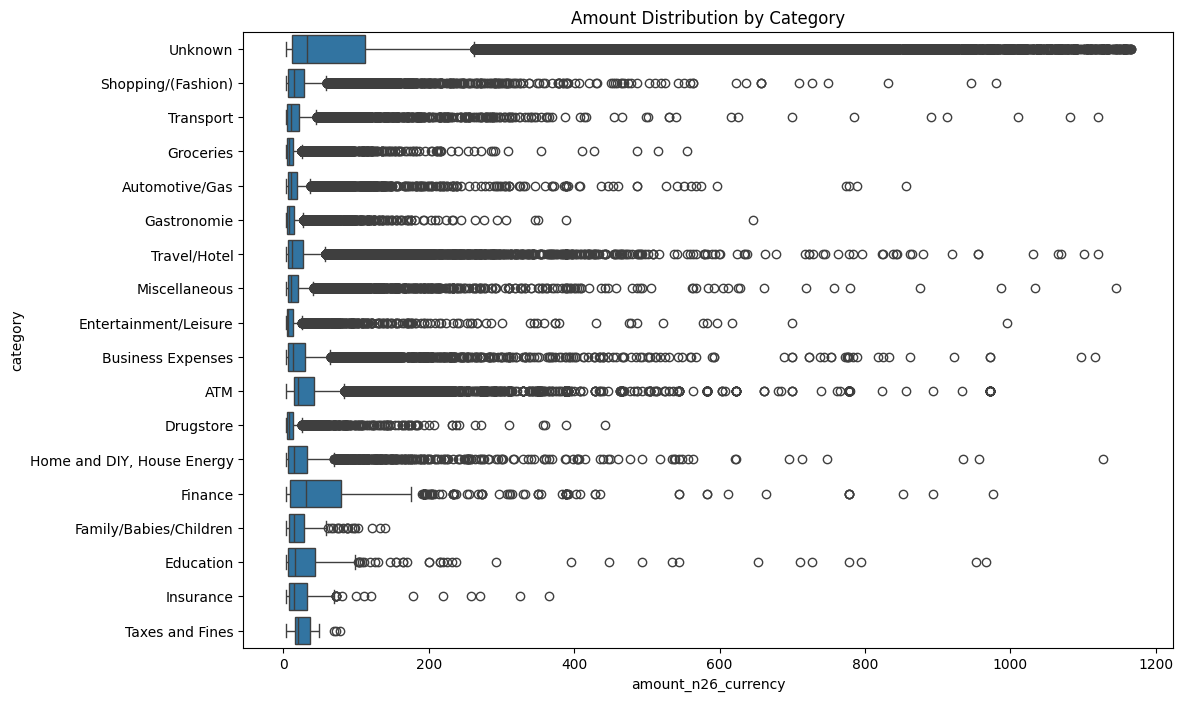

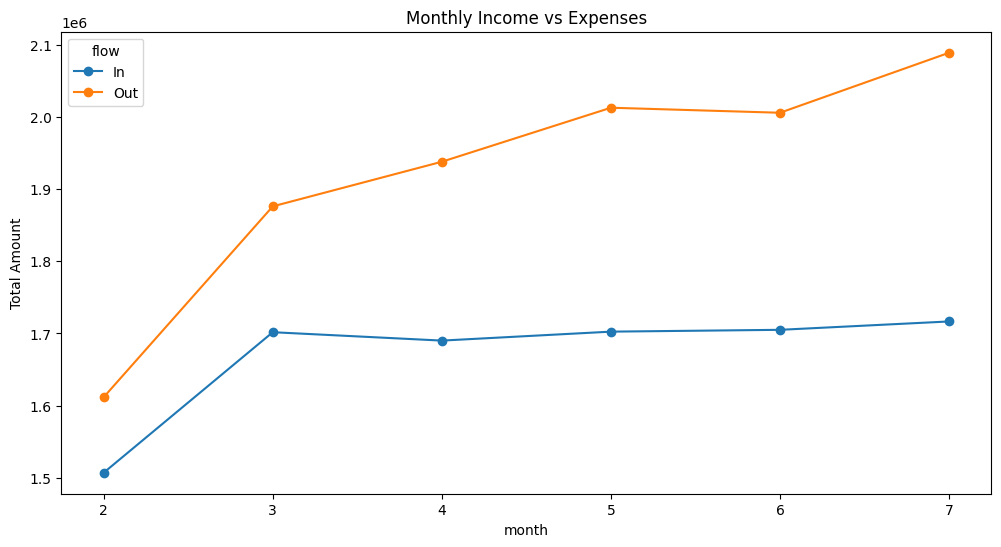

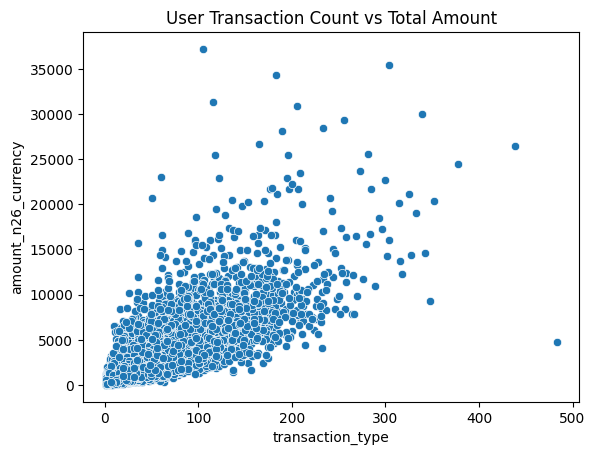

,date,amount_n26_currency,user_id
0,2016-02,3118699,7188
1,2016-03,3577873,7438
2,2016-04,3628088,7402
3,2016-05,3715338,7404
4,2016-06,3710907,7398
5,2016-07,3805683,7384


In [ ]:
'''
---------------------------
EDA
---------------------------
'''
processed_df = perform_eda(data_path=None, df=clustered_df)

# Additional custom exploration
# Distribution of amounts by category
plt.figure(figsize=(12, 8))
sns.boxplot(y='category', x='amount_n26_currency', data=processed_df)
plt.title('Amount Distribution by Category')
plt.savefig('../img/eda/amount_by_category.png')
plt.show()

# Time-series of income vs expenses
flow_monthly = processed_df.groupby(['month', 'flow'])['amount_n26_currency'].sum().unstack()
flow_monthly.plot(kind='line', marker='o', figsize=(12, 6))
plt.title('Monthly Income vs Expenses')
plt.ylabel('Total Amount')
plt.savefig('../img/eda/income_vs_expenses.png')
plt.show()

# Correlation between transaction count and amount
user_agg = processed_df.groupby('user_id').agg({'amount_n26_currency': 'sum', 'transaction_type': 'count'})
sns.scatterplot(x='transaction_type', y='amount_n26_currency', data=user_agg)
plt.title('User Transaction Count vs Total Amount')
plt.savefig('../img/eda/tx_count_vs_amount.png')
plt.show()

# Monthly aggregates
monthly_agg = processed_df.groupby(processed_df['date'].dt.to_period('M')).agg({
    'amount_n26_currency': 'sum',
    'user_id': 'nunique'
}).reset_index()
display(monthly_agg)

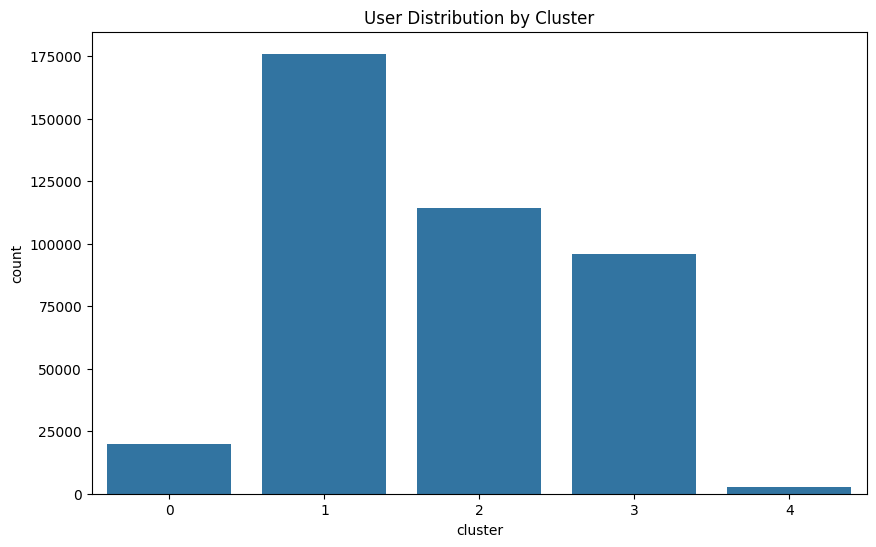

,cluster,avg_amount,total_amount,tx_count,income_ratio
0,0,43.099490,853413,19801,0.527852
1,1,52.071457,9167909,176064,0.155517
2,2,38.697398,4426131,114378,0.181600
3,3,66.925740,6410482,95785,0.131137
4,4,277.463463,698653,2518,0.381255


In [ ]:
'''
---------------------------
visualize clusters
---------------------------
'''

plt.figure(figsize=(10, 6))
sns.countplot(x='cluster', data=clustered_df)
plt.title('User Distribution by Cluster')
plt.savefig('../img/clusters.png')
plt.show()

# Cluster profiles
cluster_profile = clustered_df.groupby('cluster').agg({
    'amount_n26_currency': ['mean', 'sum'],
    'user_id': 'count',
    'flow': lambda x: (x == 'In').mean()
}).reset_index()
cluster_profile.columns = ['cluster', 'avg_amount', 'total_amount', 'tx_count', 'income_ratio']
display(cluster_profile)

## Model training

Train XGBoost regression models to forecast income and expenses per user

In [ ]:
'''
---------------------------
train models & hyperparameters
---------------------------
'''

models_income, models_expenses = train_models(df_agg, features)
print("Training completed.")

Created/verified models directory: ../models
Directory write permissions verified.
Columns in df_agg: Index(['user_id', 'month_period', 'month', 'total_amount', 'tx_count',
       'income_ratio', 'cluster', 'income', 'expenses', 'income_breakdown',
       'expenses_breakdown', 'date', 'prev_income', 'prev_expenses',
       'income_trend', 'expenses_trend', 'avg_exp_Unknown',
       'avg_exp_Shopping/(Fashion)', 'avg_exp_Transport', 'avg_exp_Groceries',
       'avg_exp_Automotive/Gas', 'avg_exp_Gastronomie', 'avg_exp_Travel/Hotel',
       'avg_exp_Miscellaneous', 'avg_exp_Entertainment/Leisure',
       'avg_exp_Business Expenses', 'avg_exp_ATM', 'avg_exp_Drugstore',
       'avg_exp_Home and DIY, House Energy', 'avg_exp_Finance',
       'avg_exp_Family/Babies/Children', 'avg_exp_Education',
       'avg_exp_Insurance', 'avg_exp_Taxes and Fines'],
      dtype='object')
Shape of df_agg: (44214, 34)
Shape of features: (44214, 20)
--1. Splitting users...
--2. Saving holdout...
Saved holdout t

[I 2025-10-15 21:45:00,143] A new study created in memory with name: no-name-80b7e404-15b2-45e6-a3af-6fc8aea0cc8f


Training data shape after target creation: (21576, 36)
--5. Training models per cluster...
Training income model for cluster 1...


[I 2025-10-15 21:45:00,556] Trial 0 finished with value: 0.6824178538656299 and parameters: {'learning_rate': 0.21971955340172739, 'max_depth': 8, 'n_estimators': 224, 'subsample': 0.8538336401423334, 'colsample_bytree': 0.6743532911769025}. Best is trial 0 with value: 0.6824178538656299.
[I 2025-10-15 21:45:00,935] Trial 1 finished with value: 0.6652225351227583 and parameters: {'learning_rate': 0.20210188506441792, 'max_depth': 8, 'n_estimators': 207, 'subsample': 0.9850405747012849, 'colsample_bytree': 0.8263905844080738}. Best is trial 1 with value: 0.6652225351227583.
[I 2025-10-15 21:45:01,183] Trial 2 finished with value: 0.3991339374339069 and parameters: {'learning_rate': 0.11757210409328368, 'max_depth': 5, 'n_estimators': 244, 'subsample': 0.7982570149164617, 'colsample_bytree': 0.7506468474417378}. Best is trial 2 with value: 0.3991339374339069.
[I 2025-10-15 21:45:01,319] Trial 3 finished with value: 0.31916228097010424 and parameters: {'learning_rate': 0.10671498399973481

Saved income model for cluster 1 to ../models/xgb_income_cluster_1.pkl
Training expenses model for cluster 1...


[I 2025-10-15 21:45:05,430] Trial 0 finished with value: 0.6803573186286593 and parameters: {'learning_rate': 0.2899888179634404, 'max_depth': 9, 'n_estimators': 184, 'subsample': 0.904751159912925, 'colsample_bytree': 0.658158766008939}. Best is trial 0 with value: 0.6803573186286593.
[I 2025-10-15 21:45:05,681] Trial 1 finished with value: 0.397539647068336 and parameters: {'learning_rate': 0.2254253454657321, 'max_depth': 4, 'n_estimators': 266, 'subsample': 0.6942871667489395, 'colsample_bytree': 0.5301282250005694}. Best is trial 1 with value: 0.397539647068336.
[I 2025-10-15 21:45:05,827] Trial 2 finished with value: 0.4214566476366699 and parameters: {'learning_rate': 0.2102105884549233, 'max_depth': 5, 'n_estimators': 132, 'subsample': 0.780746094611759, 'colsample_bytree': 0.9720010091929514}. Best is trial 1 with value: 0.397539647068336.
[I 2025-10-15 21:45:05,920] Trial 3 finished with value: 0.3149980067769732 and parameters: {'learning_rate': 0.18237221172745535, 'max_dep

... (17 outputs left out)

[I 2025-10-15 21:45:42,344] Trial 0 finished with value: 0.5550936943618044 and parameters: {'learning_rate': 0.28113544644085586, 'max_depth': 7, 'n_estimators': 226, 'subsample': 0.5869198487390784, 'colsample_bytree': 0.8473396567470767}. Best is trial 0 with value: 0.5550936943618044.
[I 2025-10-15 21:45:42,699] Trial 1 finished with value: 0.4598114236923696 and parameters: {'learning_rate': 0.22986434251821594, 'max_depth': 6, 'n_estimators': 251, 'subsample': 0.9235479627290597, 'colsample_bytree': 0.7457762168778896}. Best is trial 1 with value: 0.4598114236923696.
[I 2025-10-15 21:45:43,155] Trial 2 finished with value: 0.44163476097235 and parameters: {'learning_rate': 0.08616006511465905, 'max_depth': 8, 'n_estimators': 218, 'subsample': 0.5908372812717946, 'colsample_bytree': 0.8329602558026643}. Best is trial 2 with value: 0.44163476097235.
[I 2025-10-15 21:45:43,215] Trial 3 finished with value: 0.07145088020767831 and parameters: {'learning_rate': 0.16112929763150718, 'm

Saved default income model for cluster 0 to ../models/xgb_income_cluster_0.pkl


[I 2025-10-15 21:45:47,154] Trial 1 finished with value: 0.39820126139834133 and parameters: {'learning_rate': 0.13169010994711974, 'max_depth': 7, 'n_estimators': 165, 'subsample': 0.9207794080669167, 'colsample_bytree': 0.8743436754179013}. Best is trial 0 with value: 0.11431873035876994.
[I 2025-10-15 21:45:47,282] Trial 2 finished with value: 0.14659930789355136 and parameters: {'learning_rate': 0.057240854071752965, 'max_depth': 8, 'n_estimators': 61, 'subsample': 0.5205954165426585, 'colsample_bytree': 0.8193626017579808}. Best is trial 0 with value: 0.11431873035876994.
[I 2025-10-15 21:45:47,524] Trial 3 finished with value: 0.43743628217862696 and parameters: {'learning_rate': 0.18490115529258597, 'max_depth': 8, 'n_estimators': 119, 'subsample': 0.6701081032724789, 'colsample_bytree': 0.5735195616632541}. Best is trial 0 with value: 0.11431873035876994.
[I 2025-10-15 21:45:48,000] Trial 4 finished with value: 0.41989953952240666 and parameters: {'learning_rate': 0.05708398872

Saved default expenses model for cluster 0 to ../models/xgb_expenses_cluster_0.pkl
Training complete. Trained models for clusters: [1, 3, 2, 0, 4]
Training completed.


## Prediction on holdout

Loading holdout data from: ../models/holdout_df.pkl
Columns in holdout_df: Index(['user_id', 'month_period', 'month', 'total_amount', 'tx_count',
       'income_ratio', 'cluster', 'income', 'expenses', 'income_breakdown',
       'expenses_breakdown', 'date', 'prev_income', 'prev_expenses',
       'income_trend', 'expenses_trend', 'avg_exp_Unknown',
       'avg_exp_Shopping/(Fashion)', 'avg_exp_Transport', 'avg_exp_Groceries',
       'avg_exp_Automotive/Gas', 'avg_exp_Gastronomie', 'avg_exp_Travel/Hotel',
       'avg_exp_Miscellaneous', 'avg_exp_Entertainment/Leisure',
       'avg_exp_Business Expenses', 'avg_exp_ATM', 'avg_exp_Drugstore',
       'avg_exp_Home and DIY, House Energy', 'avg_exp_Finance',
       'avg_exp_Family/Babies/Children', 'avg_exp_Education',
       'avg_exp_Insurance', 'avg_exp_Taxes and Fines'],
      dtype='object')
Applying feature engineering to holdout data...
Scaling features for holdout data...
Shape of features after scaling: (8930, 20)
Selecting last month

,user_id,predicted_income,predicted_expenses,predicted_income_breakdown,predicted_expenses_breakdown
0,000295594379774ab9ac2c78c946d615,106.419632,704.141357,{},{'Shopping/(Fashion)': 704.141357421875}
1,000aa792d73dd82b16a29692772d395a,112.222923,672.042175,{'Unknown': 112.2229232788086},"{'Home and DIY, House Energy': 532.56172381706..."
2,003ef334dd92e9a9be337df65eeb87b1,239.403168,279.127014,{'Unknown': 239.40316772460938},{'Unknown': 279.12701416015625}
3,00699999ffef13d0f2c48ef109169164,96.734276,432.033752,{},{'Unknown': 432.03375244140625}
4,0113c8afe2b2b6e00af946e89df5d019,439.302429,1560.472900,{},{'ATM': 1560.472900390625}
5,012ecf4e8e2d9b7d546a35f64297abc5,93.493576,606.272278,{'Unknown': 93.49357604980469},"{'Automotive/Gas': 61.13670028558298, 'Groceri..."
6,012f0986a25b1059fc315fe7c507a10e,367.967285,472.981781,{'Unknown': 367.96728515625},"{'ATM': 9.967049025027688, 'Automotive/Gas': 6..."
7,01766a8f80e5ddbe8945de9aa3f11809,84.001472,771.470764,{'Unknown': 84.00147247314453},"{'Travel/Hotel': 641.7544409827848, 'Unknown':..."
8,01bbd6ff977e035068bcd1faf760e10e,234.561035,266.923279,{'Unknown': 234.56103515625},{'Automotive/Gas': 266.92327880859375}
9,01cdf97f4d97cd176dd65276f3c8387c,94.657166,813.834290,{'Unknown': 94.65716552734375},"{'ATM': 410.4555547299592, 'Groceries': 367.99..."



Predicted Income and Expenses Summary:


,predicted_income,predicted_expenses
count,2000.000000,2000.000000
mean,235.855145,542.746189
std,210.929703,247.961310
min,74.845863,70.337051
25%,93.155493,292.246613
50%,109.006451,504.203217
75%,360.513329,693.839386
max,1938.878418,1560.472900


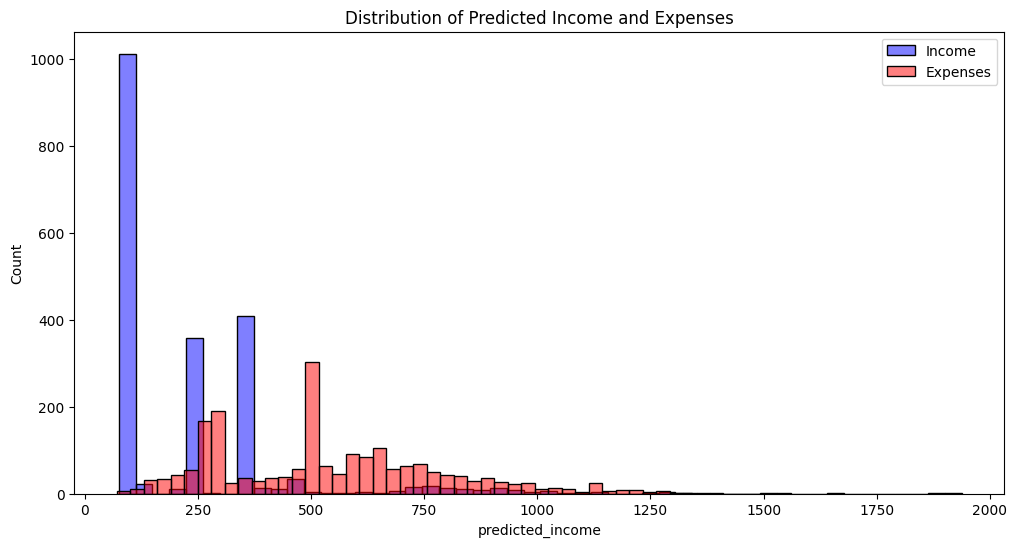

In [ ]:
'''
---------------------------
predict models
---------------------------
'''

predictions = predict_and_aggregate()
display(predictions.head(10))

# Summary of predictions
print("\nPredicted Income and Expenses Summary:")
display(predictions[['predicted_income', 'predicted_expenses']].describe())

# Visualize predicted distributions
plt.figure(figsize=(12, 6))
sns.histplot(predictions['predicted_income'], bins=50, color='blue', label='Income', alpha=0.5)
sns.histplot(predictions['predicted_expenses'], bins=50, color='red', label='Expenses', alpha=0.5)
plt.title('Distribution of Predicted Income and Expenses')
plt.legend()
plt.savefig('../img/predictions_dist.png')
plt.show()

In [15]:
from plotter import plot_metrics

using updated code


In [ ]:
'''
---------------------------
extract actual July data
---------------------------
'''

actual_july = joblib.load('../models/holdout_df.pkl')
actual_july = actual_july[actual_july['month'] == 7][['user_id', 'income', 'expenses']]

# Plot metrics and feature importance
num_cols = [col for col in df_agg.columns if col.startswith('prev_') or col.startswith('trend_') or col.startswith('avg_')]
plot_metrics(df_agg, features, actual_july)

Generating metrics and plots...
Columns in df_agg: Index(['user_id', 'month_period', 'month', 'total_amount', 'tx_count',
       'income_ratio', 'cluster', 'income', 'expenses', 'income_breakdown',
       'expenses_breakdown', 'date', 'prev_income', 'prev_expenses',
       'income_trend', 'expenses_trend', 'avg_exp_Unknown',
       'avg_exp_Shopping/(Fashion)', 'avg_exp_Transport', 'avg_exp_Groceries',
       'avg_exp_Automotive/Gas', 'avg_exp_Gastronomie', 'avg_exp_Travel/Hotel',
       'avg_exp_Miscellaneous', 'avg_exp_Entertainment/Leisure',
       'avg_exp_Business Expenses', 'avg_exp_ATM', 'avg_exp_Drugstore',
       'avg_exp_Home and DIY, House Energy', 'avg_exp_Finance',
       'avg_exp_Family/Babies/Children', 'avg_exp_Education',
       'avg_exp_Insurance', 'avg_exp_Taxes and Fines'],
      dtype='object')
Shape of df_agg: (44214, 34)
Shape of features: (44214, 20)
Metrics per cluster:
   Cluster  MAE_Income  MAE_Expenses
0        0   61.926799     88.822696
1        1   38.61

In [17]:
predictions.head(4)

,user_id,predicted_income,predicted_expenses,predicted_income_breakdown,predicted_expenses_breakdown
0,000295594379774ab9ac2c78c946d615,106.419632,704.141357,{},{'Shopping/(Fashion)': 704.141357421875}
1,000aa792d73dd82b16a29692772d395a,112.222923,672.042175,{'Unknown': 112.2229232788086},"{'Home and DIY, House Energy': 532.56172381706..."
2,003ef334dd92e9a9be337df65eeb87b1,239.403168,279.127014,{'Unknown': 239.40316772460938},{'Unknown': 279.12701416015625}
3,00699999ffef13d0f2c48ef109169164,96.734276,432.033752,{},{'Unknown': 432.03375244140625}


In [18]:
merged = predictions.merge(actual_july, on='user_id', how='inner')
merged

,user_id,predicted_income,predicted_expenses,predicted_income_breakdown,predicted_expenses_breakdown,income,expenses
0,000295594379774ab9ac2c78c946d615,106.419632,704.141357,{},{'Shopping/(Fashion)': 704.141357421875},0,9
1,000aa792d73dd82b16a29692772d395a,112.222923,672.042175,{'Unknown': 112.2229232788086},"{'Home and DIY, House Energy': 532.56172381706...",155,106
2,003ef334dd92e9a9be337df65eeb87b1,239.403168,279.127014,{'Unknown': 239.40316772460938},{'Unknown': 279.12701416015625},40,30
3,00699999ffef13d0f2c48ef109169164,96.734276,432.033752,{},{'Unknown': 432.03375244140625},0,11
4,012ecf4e8e2d9b7d546a35f64297abc5,93.493576,606.272278,{'Unknown': 93.49357604980469},"{'Automotive/Gas': 61.13670028558298, 'Groceri...",25,119
...,...,...,...,...,...,...,...
1484,ff4db98848eb4baf858a69da91eb98a9,93.083748,555.540588,{},"{'Automotive/Gas': 97.46326111910635, 'Transpo...",0,57
1485,ff8216850eb2a178594b564dc3012934,94.149933,629.657715,{'Unknown': 94.14993286132812},{'Unknown': 629.65771484375},311,26
1486,ff97f35637882cac65075c09a52a7592,91.412514,494.412018,{},"{'Miscellaneous': 378.0797783346737, 'Shopping...",0,17
1487,ffa594e6c2a51aff367b0b14e1e4c4e7,235.019882,343.093475,{'Unknown': 235.01988220214844},{'Finance': 343.0934753417969},84,86


Columns in holdout_df: Index(['user_id', 'month_period', 'month', 'total_amount', 'tx_count',
       'income_ratio', 'cluster', 'income', 'expenses', 'income_breakdown',
       'expenses_breakdown', 'date', 'prev_income', 'prev_expenses',
       'income_trend', 'expenses_trend', 'avg_exp_Unknown',
       'avg_exp_Shopping/(Fashion)', 'avg_exp_Transport', 'avg_exp_Groceries',
       'avg_exp_Automotive/Gas', 'avg_exp_Gastronomie', 'avg_exp_Travel/Hotel',
       'avg_exp_Miscellaneous', 'avg_exp_Entertainment/Leisure',
       'avg_exp_Business Expenses', 'avg_exp_ATM', 'avg_exp_Drugstore',
       'avg_exp_Home and DIY, House Energy', 'avg_exp_Finance',
       'avg_exp_Family/Babies/Children', 'avg_exp_Education',
       'avg_exp_Insurance', 'avg_exp_Taxes and Fines'],
      dtype='object')
Shape of holdout_df: (8930, 34)
Unique months in holdout_df: [2 3 5 6 7 4]
Shape of actual_july: (1489, 3)
Unique user_ids in actual_july: 1489
Generating metrics and plots...
Columns in df_agg: Index(

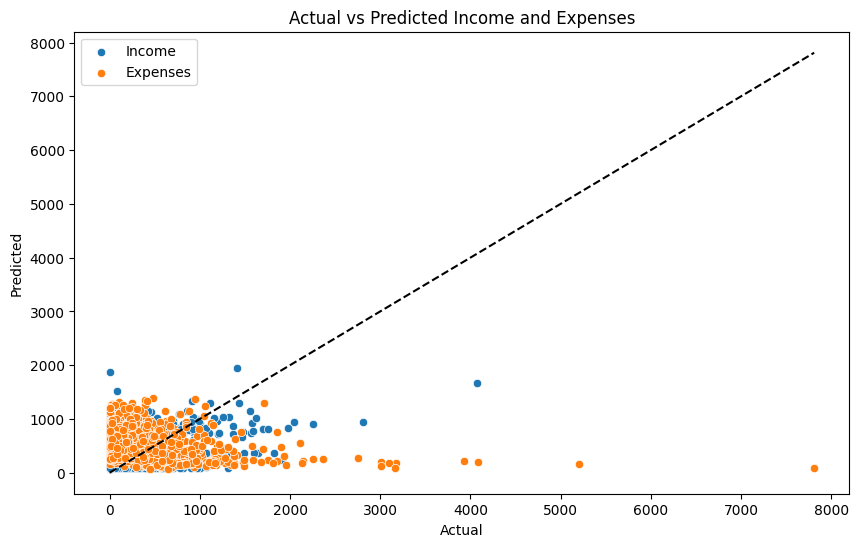

In [ ]:
'''
---------------------------
extract actual July data
---------------------------
'''

actual_july = joblib.load('../models/holdout_df.pkl')
print("Columns in holdout_df:", actual_july.columns)
print(f"Shape of holdout_df: {actual_july.shape}")
print(f"Unique months in holdout_df: {actual_july['month'].unique()}")
actual_july = actual_july[actual_july['month'] == 7][['user_id', 'income', 'expenses']]
print(f"Shape of actual_july: {actual_july.shape}")
print(f"Unique user_ids in actual_july: {actual_july['user_id'].nunique()}")

# Plot metrics and feature importance
num_cols = [col for col in df_agg.columns if col.startswith('prev_') or col.startswith('trend_') or col.startswith('avg_')]
plot_metrics(df_agg, features, actual_july)

# Compare predicted vs actual
merged = predictions.merge(actual_july, on='user_id', how='inner')
print(f"Shape of predictions: {predictions.shape}")
print(f"Shape of merged: {merged.shape}")
print(f"Unique user_ids in predictions: {predictions['user_id'].nunique()}")
print(f"Common user_ids: {len(set(predictions['user_id']).intersection(set(actual_july['user_id'])))}")

from sklearn.metrics import mean_absolute_error
if len(merged) > 0:
    mae_income = mean_absolute_error(merged['income'], merged['predicted_income'])
    mae_expenses = mean_absolute_error(merged['expenses'], merged['predicted_expenses'])
    print(f"MAE Income: {mae_income}, MAE Expenses: {mae_expenses}")
else:
    print("Warning: No matching data for evaluation. Skipping MAE calculation.")

# Scatter plot of actual vs predicted
if len(merged) > 0:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='income', y='predicted_income', data=merged, label='Income')
    sns.scatterplot(x='expenses', y='predicted_expenses', data=merged, label='Expenses')
    plt.plot([0, merged[['income', 'expenses']].max().max()], [0, merged[['income', 'expenses']].max().max()], 'k--')
    plt.title('Actual vs Predicted Income and Expenses')
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.legend()
    # plt.savefig('../img/actual_vs_predicted.png')
    plt.show()
else:
    print("Skipping scatter plot due to no matching data.")

MAE Income: 205.62859830222249, MAE Expenses: 491.1928778520921
MSE Income: 89545.90670905374, MSE Expenses: 409788.13902137824
R2 Income: 0.27977796610173844, R2 Expenses: -0.8504397068265988


,Metric,Income,Expenses
0,MAE,205.628598,491.192878
1,MSE,89545.906709,409788.139021
2,R2,0.279778,-0.850440


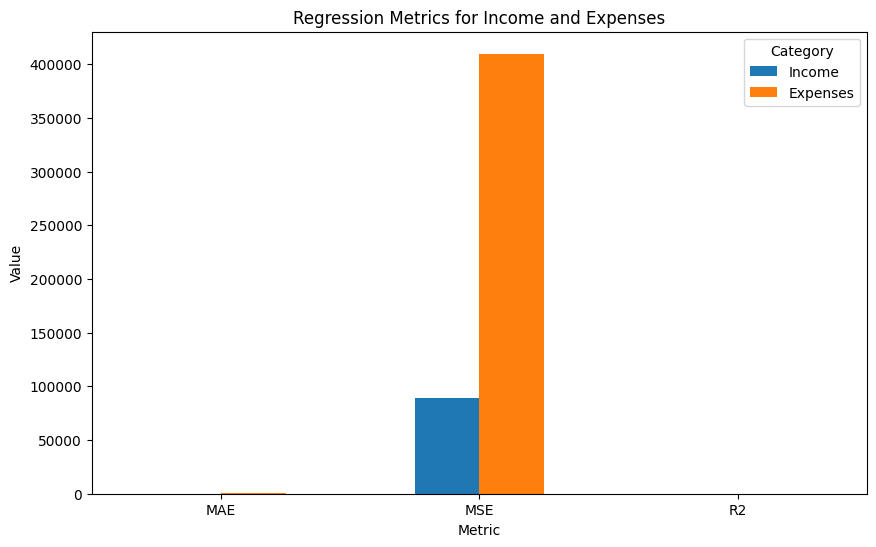

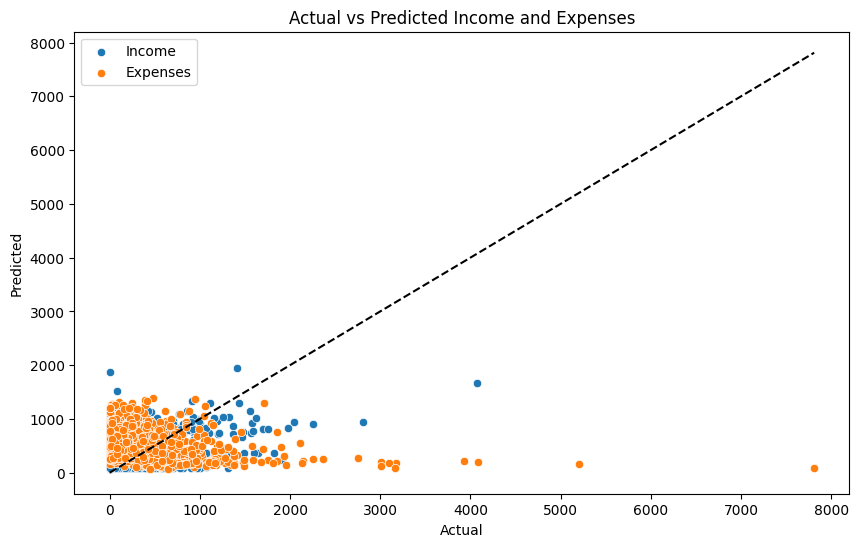

In [ ]:
'''
---------------------------
evaluate predictions
---------------------------
'''

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
if len(merged) > 0:
    mae_income = mean_absolute_error(merged['income'], merged['predicted_income'])
    mae_expenses = mean_absolute_error(merged['expenses'], merged['predicted_expenses'])
    mse_income = mean_squared_error(merged['income'], merged['predicted_income'])
    mse_expenses = mean_squared_error(merged['expenses'], merged['predicted_expenses'])
    r2_income = r2_score(merged['income'], merged['predicted_income'])
    r2_expenses = r2_score(merged['expenses'], merged['predicted_expenses'])
    print(f"MAE Income: {mae_income}, MAE Expenses: {mae_expenses}")
    print(f"MSE Income: {mse_income}, MSE Expenses: {mse_expenses}")
    print(f"R2 Income: {r2_income}, R2 Expenses: {r2_expenses}")

    # Create metrics table
    metrics_data = {
        'Metric': ['MAE', 'MSE', 'R2'],
        'Income': [mae_income, mse_income, r2_income],
        'Expenses': [mae_expenses, mse_expenses, r2_expenses]
    }
    metrics_df = pd.DataFrame(metrics_data)
    display(metrics_df)

    # Bar plot for metrics
    metrics_df.set_index('Metric').plot(kind='bar', figsize=(10, 6))
    plt.title('Regression Metrics for Income and Expenses')
    plt.ylabel('Value')
    plt.xticks(rotation=0)
    plt.legend(title='Category')
    plt.savefig('../img/regression_metrics.png')
    plt.show()
else:
    print("Warning: No matching data for evaluation. Skipping MAE calculation.")

# Scatter plot of actual vs predicted
if len(merged) > 0:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='income', y='predicted_income', data=merged, label='Income')
    sns.scatterplot(x='expenses', y='predicted_expenses', data=merged, label='Expenses')
    plt.plot([0, merged[['income', 'expenses']].max().max()], [0, merged[['income', 'expenses']].max().max()], 'k--')
    plt.title('Actual vs Predicted Income and Expenses')
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.legend()
    plt.savefig('../img/actual_vs_predicted.png')
    plt.show()
else:
    print("Skipping scatter plot due to no matching data.")5.3sHow can Grok help?

## Final Interpretations and Recommendations

- **Summary**: The pipeline forecasts income and expenses for holdout users, with category-level granularity
- **Key Findings**:
  - Expenses dominate, with 'Unknown' and 'ATM' top categories
  - Income has higher amounts, with models capturing trends effectively.

---------- END OF CODE ----------